# Projection and Label Transfer

This tutorial demonstrates how to project other datasets into HypoMap3D's single cell embedding space for label transfer.

In this notebook, we will:
1. Project query cells (such as your own data) into HypoMap3D's embedding space (scArches)
2. Transfer labels and membership probabilities 
3. Project the query cells into HypoMap3D's UMAP space

Requirements:
1. HypoMap3D's code base and environment. For this, follow the instructions at the root of the Git repo.
2. HypoMap3D projection reference adata. Download it and place it into DATADIR/9_objects/singlecell/projection_anndatas/hypomap3d_sc_control_projection_only.h5ad 
3. HypoMap3D's scVI model. Download it and place it into DATADIR/9_objects/scvi/model.pt
4. Your own query dataset. If you do not bring your own dataset the notebook will run on a test case derived from the HypoMap3D single-cell atlas. For this, you would have to download the object and place it into DATADIR/9_objects/singlecell/hypomap3d_singlecell_all.h5ad.

Of course, the above paths can be modified but then they have to be changed accordingly below as well.

### Imports

In [1]:
from pathlib import Path
import warnings
import os 

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scvi
import matplotlib.pyplot as plt
from dotenv import dotenv_values
import torch
import scipy.sparse as sp

from hm3d_utils.manifold import project_to_ref_umap
from hm3d_utils.clustering import project_query

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)
scvi.settings.seed = 12345

use_gpu = torch.cuda.is_available()
print(f"GPU is available: {use_gpu}")

Seed set to 12345


GPU is available: True


### File paths

The following ones are automatic and only require a change if you downloaded the files somewhere else.

In [ ]:
CONFIG = dotenv_values("config.env") # file at the root of your cloned repo
DATADIR = Path(CONFIG['DATADIR']) # root of your DATADIR

# Path to director of scVI model
SCVI_DIR  = DATADIR / "9_objects" / "scvi"

# Path to reference object
REF_FP = DATADIR / "9_objects" / "singlecell" / "projection_anndatas" /  "hypomap3d_sc_control_projection_only.h5ad" 

The following cell contains the path to your data, so change the path accordingly, and remove the "#". 

In this notebook, we will use the non-control cells from the Gutgesell dataset for demonstration if QUERY_FP remains undefined.

In [3]:
# QUERY_FP = Path("path/to/your/data.h5ad") #change and uncomment me if you want to use your own data

# Data loading

Let's load the reference (HypoMap3D)

In [4]:
ref_adata = sc.read_h5ad(REF_FP) 

In [5]:
ref_adata

AnnData object with n_obs × n_vars = 896959 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'
    obsp: '50nn_adjacencies'

Let's load the query adata.

If you provided the path to your object above it will be used. 

Otherwise, a subset of HypoMap3D's non-control data will be used, deleting some genes in the process as to simulate a dataset that might not cover all of HypoMap3D's feature space.

In [6]:
if "QUERY_FP" in globals():
    query_adata = sc.read_h5ad(QUERY_FP) #load user dataset
else:
    import random
    DUMMY_QUERY_FP = DATADIR / "9_objects" / "singlecell" / "hypomap3d_singlecell_all.h5ad" 
    query_adata = sc.read_h5ad(DUMMY_QUERY_FP, backed="r")

    # Randomly remove 10% of HypoMap3D's HVGs
    hvgs = ref_adata.var.loc[ref_adata.var.IsHvg].index.to_list()
    genes_to_remove = set(random.sample(hvgs, k=len(hvgs) // 10))

    gene_subset = [g for g in query_adata.var_names if g not in genes_to_remove]

    # Load non-control cells of Gutgesell dataset
    query_adata = query_adata[
        (query_adata.obs.Dataset == "SC2-25") & (~query_adata.obs.IsControl),
        gene_subset
    ].to_memory()

    # Remove information to get barebone query
    query_adata.obs = query_adata.obs.loc[:, ["CellID", "Sample"]]
    del query_adata.obsm

In [7]:
query_adata

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'

# scArches projection

## Preparation

### Raw counts sanity check

scArches operates on raw counts, so you need to ensure that query_adata.X contains raw counts!

Here, we just print the frequency distribution of some gene count values for simplicity.

In [8]:
value_counts = pd.Series(query_adata[:100,:100].X.toarray().flatten()).value_counts().sort_index() 
value_counts.head(10)

0.0    9634
1.0     166
2.0      52
3.0      32
4.0      29
5.0      12
6.0      18
7.0       6
8.0      11
9.0       9
Name: count, dtype: int64

In [9]:
value_counts.tail(10)

14.0    2
18.0    2
19.0    3
22.0    1
23.0    1
24.0    1
27.0    1
28.0    1
37.0    1
48.0    1
Name: count, dtype: int64

All numbers on the left are floats with 0 as decimals --> raw counts. 

### Setting batch column

Next, we must set the batch column for scArches. This will be the .obs column specifying your sample for instance

In [10]:
query_adata.obs.head(2)

,CellID,Sample
SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599
SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599


In [11]:
BATCH_COL = "Sample" # change me if your data uses a different name

The problem is that the name of the batch column MUST be "Sample" due to the model specifications.

Hence, we use your provided BATCH_COL, replacing its column name with Sample in the query adata.

DO not worry, the object that is being saved later is the object with all genes. Hence, your previous column name will be maintained. 

In [12]:
query_adata.obs = query_adata.obs.rename(columns={BATCH_COL: "Sample"})

### Removing low quality cells 

The cell type label transfer hinges on having sufficient gene expression counts in HypoMap3D's highly variable genes (HVGs). 

Hence, we remove cells with less than 100 total counts in HypoMap3D's HVGs.

In [13]:
hvgs = ref_adata.var.loc[ref_adata.var["IsHvg"]].index

hvgs_available = query_adata.var_names.intersection(hvgs)

if len(hvgs_available) == 0:
    raise ValueError("No shared HVGs between reference and query.")

hvg_counts = np.asarray(
    query_adata[:, hvgs_available].X.sum(axis=1)
).ravel()

keep_mask = hvg_counts > 100


In [14]:
print(f"{np.sum(~keep_mask)} cells will be removed")

0 cells will be removed


In [15]:
query_adata = query_adata[keep_mask, :].copy()

### Copy query data with all genes

Non-HVGs are lost during the projection, so let's keep a version that has all genes for later.

In [16]:
query_all_genes = query_adata.copy()

In [17]:
query_adata

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'

### Query preparation according to model

In [18]:
# prepare query adata
query_adata = scvi.model.SCVI.prepare_query_anndata(query_adata, str(SCVI_DIR), inplace = False)

INFO     File /REDACTED-path/HypoMap3D-data/v1.0/9_objects/scvi/model.pt already downloaded           


INFO     Found 90.0% reference vars in query data.                                                                 


In [19]:
# create the new query model instance.
vae_query = scvi.model.SCVI.load_query_data(
    query_adata,
    str(SCVI_DIR)
)

# train
vae_query.train(max_epochs=20, plan_kwargs=dict(weight_decay=0.0))

INFO     File /REDACTED-path/HypoMap3D-data/v1.0/9_objects/scvi/model.pt already downloaded           


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A40') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader`

Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


In [20]:
# get latent representation into query adata that has all genes
query_all_genes.obsm["X_embed"] = vae_query.get_latent_representation()

# Label transfer

### Step 1: Let's get membership probabilities for L5 cell types

This is performed by the project_query function in a hierarchy-aware manner where the most probable path along the clustering tree is chosen.

In [21]:
PATH_KEYS = ['L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID']

pathmat, P_path = project_query(
    ref_adata,
    query_all_genes,
    path_keys=PATH_KEYS,
    k=50,
    use_rep='X_embed',
    use_gpu=use_gpu
)


The output of the project query function is a matrix of shape (n_cells, n_unique_L5_labels) containing the cell type membership probabilities for all L5 cell types.

In [22]:
P_path

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 355999 stored elements and shape (121626, 932)>

Further, pathmat tells us the paths from L1 to L5 along our clustering tree for each of the n_unique_L5_labels.

In [23]:
pathmat

array([['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-319', 'Gb5-428'],
       ['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-320', 'Gb5-429'],
       ['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-321', 'Gb5-430'],
       ...,
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-44', 'NN5-44'],
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-45', 'NN5-45'],
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-46', 'NN5-46']],
      shape=(932, 5), dtype=object)

Pathmat will be used used later, so let us keep it in the adata.

In [24]:
query_all_genes.uns['pathmat'] = pathmat

### Step 2: Let's get hard cell type assignments for all levels

Furthermore, we add level-specific path probabilities for convenience.

Here, we add up cell type membership probabilities of all leaf cell types in a given branch to create the membership probabilities of the above levels.

So for a given L4 cell type, we sum up the probabilities of all its L5 subclusters.

The same operation is performed up until L1.

In [25]:
# Get index of best path for each query cell
best_path_idx = np.asarray(np.argmax(P_path, axis=1)).flatten()

# Iterate over each hierarchical level and assign hard and soft labels to query cells
for i, level_id_key in enumerate(PATH_KEYS):

    # Derive level key from level ID key
    level_key = level_id_key.replace('_ID', '')

    # ------------------------ Get Hard Label Assignments ------------------------ #

    # Get all possible labels that can be assigned from the corresponding reference level
    level_categories = ref_adata.obs[level_id_key].cat.categories.tolist()
    query_all_genes.uns[level_id_key] = level_categories # store in .uns for later pathmat usage

    # We assign the label for each query cell at this level based on the winning path
    query_all_genes.obs[f"{level_id_key}_assigned"] = pd.Series(
        pathmat[:, i][best_path_idx],
        index=query_all_genes.obs_names
    ).astype(pd.CategoricalDtype(categories=level_categories))

    # ------------------------ Get Soft Label Confidences ------------------------ #

    cell_indices = np.arange(query_all_genes.shape[0])

    # Construct Adjacency matrix between current level and lowest level
    category_to_idx = {cat: i for i, cat in enumerate(level_categories)}
    inv = np.array([category_to_idx[x] for x in pathmat[:, i]])
    A = sp.csc_matrix(
        inv[:, None] == np.arange(len(level_categories)),
        dtype=bool
    )

    P_level = P_path @ A # convert (n_cells, nPaths) to (n_cells, nLevelClusters)
    query_all_genes.obsm[f"P_{level_key}"] = P_level # save to .obsm for later usage (csr matrix)

    # Get probability of hard assigned label
    assigned_label_idx = query_all_genes.obs[f"{level_id_key}_assigned"].cat.codes.values
    query_all_genes.obs[f'{level_key}_assigned_p'] = np.asarray(
        P_level[cell_indices, assigned_label_idx]
    ).flatten()

    # -------------------------- Descriptive Annotations ------------------------- #

    # Build map from ID to descriptive annotation
    categories_decr = ref_adata.obs[f"{level_key}_descr"].cat.categories.tolist()
    map_descr = {annotation.split(' ')[0]: annotation for annotation in categories_decr}

    # Map cell annotations
    query_all_genes.obs[f'{level_key}_descr_assigned'] = [
        map_descr[label] for label in query_all_genes.obs[f"{level_id_key}_assigned"]
    ]

    # Map category lookup
    query_all_genes.uns[f"{level_key}_descr"] = [
        map_descr[id_] for id_ in query_all_genes.uns[level_id_key]
    ]

    # ------------------------------ ABC Annotations ----------------------------- #

    # Build map from ID to ABC-like annotation
    categories_abc = ref_adata.obs[f"{level_key}_abc_like"].cat.categories.tolist()
    map_abc = {annotation.split(' ')[0]: annotation for annotation in categories_abc}

    # Map cell ABC-like annotations
    query_all_genes.obs[f'{level_key}_abc_like_assigned'] = [
        map_abc[label] for label in query_all_genes.obs[f"{level_id_key}_assigned"]
    ]

    # Map ABC-like annotations for the category lookup in .uns
    query_all_genes.uns[f"{level_key}_abc_like"] = [
        map_abc[id_] for id_ in query_all_genes.uns[level_id_key]
    ]



In [26]:
query_all_genes

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample', 'L1_ID_assigned', 'L1_assigned_p', 'L1_descr_assigned', 'L1_abc_like_assigned', 'L2_ID_assigned', 'L2_assigned_p', 'L2_descr_assigned', 'L2_abc_like_assigned', 'L3_ID_assigned', 'L3_assigned_p', 'L3_descr_assigned', 'L3_abc_like_assigned', 'L4_ID_assigned', 'L4_assigned_p', 'L4_descr_assigned', 'L4_abc_like_assigned', 'L5_ID_assigned', 'L5_assigned_p', 'L5_descr_assigned', 'L5_abc_like_assigned'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'pathmat', 'L1_ID', 'L1_descr', 'L1_abc_like', 'L2_ID', 'L2_descr', 'L2_abc_like', 'L3_ID', 'L3_descr', 'L3_abc_like', 'L4_ID', 'L4_descr', 'L4_abc_like', 'L5_ID', 'L5_descr', 'L5_abc_like'
    obsm: 'X_embed', 'P_L1', 'P_L2', 'P_L3', 'P_L4', 'P_L5'

Now, the most likely labels for L1-L5 along with their confidences are in .obs.

For instance, L2_abc_like_assigned and L2_descr_assigned are the most probable abc-like and short-form labels for L2 with L2_assigned_p specifying the membership probability (= confidence).

In [27]:
query_all_genes.obs.head(2)

,CellID,Sample,L1_ID_assigned,L1_assigned_p,L1_descr_assigned,L1_abc_like_assigned,L2_ID_assigned,L2_assigned_p,L2_descr_assigned,L2_abc_like_assigned,...,L3_descr_assigned,L3_abc_like_assigned,L4_ID_assigned,L4_assigned_p,L4_descr_assigned,L4_abc_like_assigned,L5_ID_assigned,L5_assigned_p,L5_descr_assigned,L5_abc_like_assigned
SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599,Gl1-1,1.0,Gl1-1 Glut,Gl1-1 Glut,Gl2-4,1.0,Gl2-4 STN-PSTN Pitx2.Angpt1,Gl2-4 STN-PSTN Pitx2 Angpt1 Glut,...,Gl3-8 PSTN Egfem1,Gl3-8 STN-PSTN Pitx2 Angpt1 Glut_1,Gl4-17,1.0,Gl4-17 PSTN Egfem1.Grp,Gl4-17 STN-PSTN Pitx2 Angpt1 Glut_1-3,Gl5-20,1.0,Gl5-20 PSTN Egfem1.Grp,Gl5-20 STN-PSTN Pitx2 Angpt1 Glut_1-3-1
SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599,NN1-1,1.0,NN1-1 OPC-Oligo,NN1-1 OPC-Oligo,NN2-1,1.0,NN2-1 Oligo_1,NN2-1 Oligo_1,...,NN3-1 Oligo_1_1,NN3-1 Oligo_1_1,NN4-1,1.0,NN4-1 Oligo_1_1-1,NN4-1 Oligo_1_1-1,NN5-1,1.0,NN5-1 Oligo_1_1-1,NN5-1 Oligo_1_1-1


Membership probabilities for all cell types are in .obsm, with one matrix per level.

For instance, for L3:

In [28]:
query_all_genes.obsm["P_L3"]

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 223202 stored elements and shape (121626, 274)>

The cell type labels are stored in .uns:

In [29]:
query_all_genes.uns["L3_descr"][:10] # printing just the first 10

['Gb3-124 MPO Meis1',
 'Gb3-125 SI Lgr5',
 'Gb3-126 MPO Sema3d',
 'Gb3-127 MPO Penk',
 'Gb3-128 SI Chat',
 'Gb3-129 NDB Fign',
 'Gb3-130 ZI Hmcn1',
 'Gb3-131 LHA Arx',
 'Gb3-132 CP Nfix',
 'Gb3-133 ZI Onecut3']

So, if you would want to get the membership probability for the cell type "Gb3-228 ARH Agrp" of a particular cell you could use:

In [30]:
agrp_idx = list(query_all_genes.uns["L3_ID"]).index("Gb3-228")
cell_idx = 5 # let's just use the sixth cell here as an example

p_agrp = query_all_genes.obsm["P_L3"][cell_idx, agrp_idx]
p_agrp

np.float32(0.0)

Looks like that cell is not an AgRP neuron!

# Common UMAP

Now we will project the query data into UMAP space of HypoMap3D for some sweet plots.

In [31]:
# Saving previous UMAP coordinates as to not overwrite them
if "X_umap" in query_all_genes.obsm.keys():
    query_all_genes.obsm["X_umap_own"] = query_all_genes.obsm["X_umap"].copy()

In [32]:
query_all_genes.obsm['X_umap'], _ = project_to_ref_umap(
    ref_adata.obsm['X_embed'], # ref embedding
    query_all_genes.obsm['X_embed'], # query embedding
    ref_adata.obsm['X_umap'], # ref umap
    spread=1.0,
    min_dist=0.5,
    verbose=True,
    use_gpu=use_gpu,
    n_epochs=100,
    seed=0
)

  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs


Let's plot your cells on HypoMap3D background

... storing 'L1_descr_assigned' as categorical
... storing 'L1_abc_like_assigned' as categorical
... storing 'L2_descr_assigned' as categorical
... storing 'L2_abc_like_assigned' as categorical
... storing 'L3_descr_assigned' as categorical
... storing 'L3_abc_like_assigned' as categorical
... storing 'L4_descr_assigned' as categorical
... storing 'L4_abc_like_assigned' as categorical
... storing 'L5_descr_assigned' as categorical
... storing 'L5_abc_like_assigned' as categorical


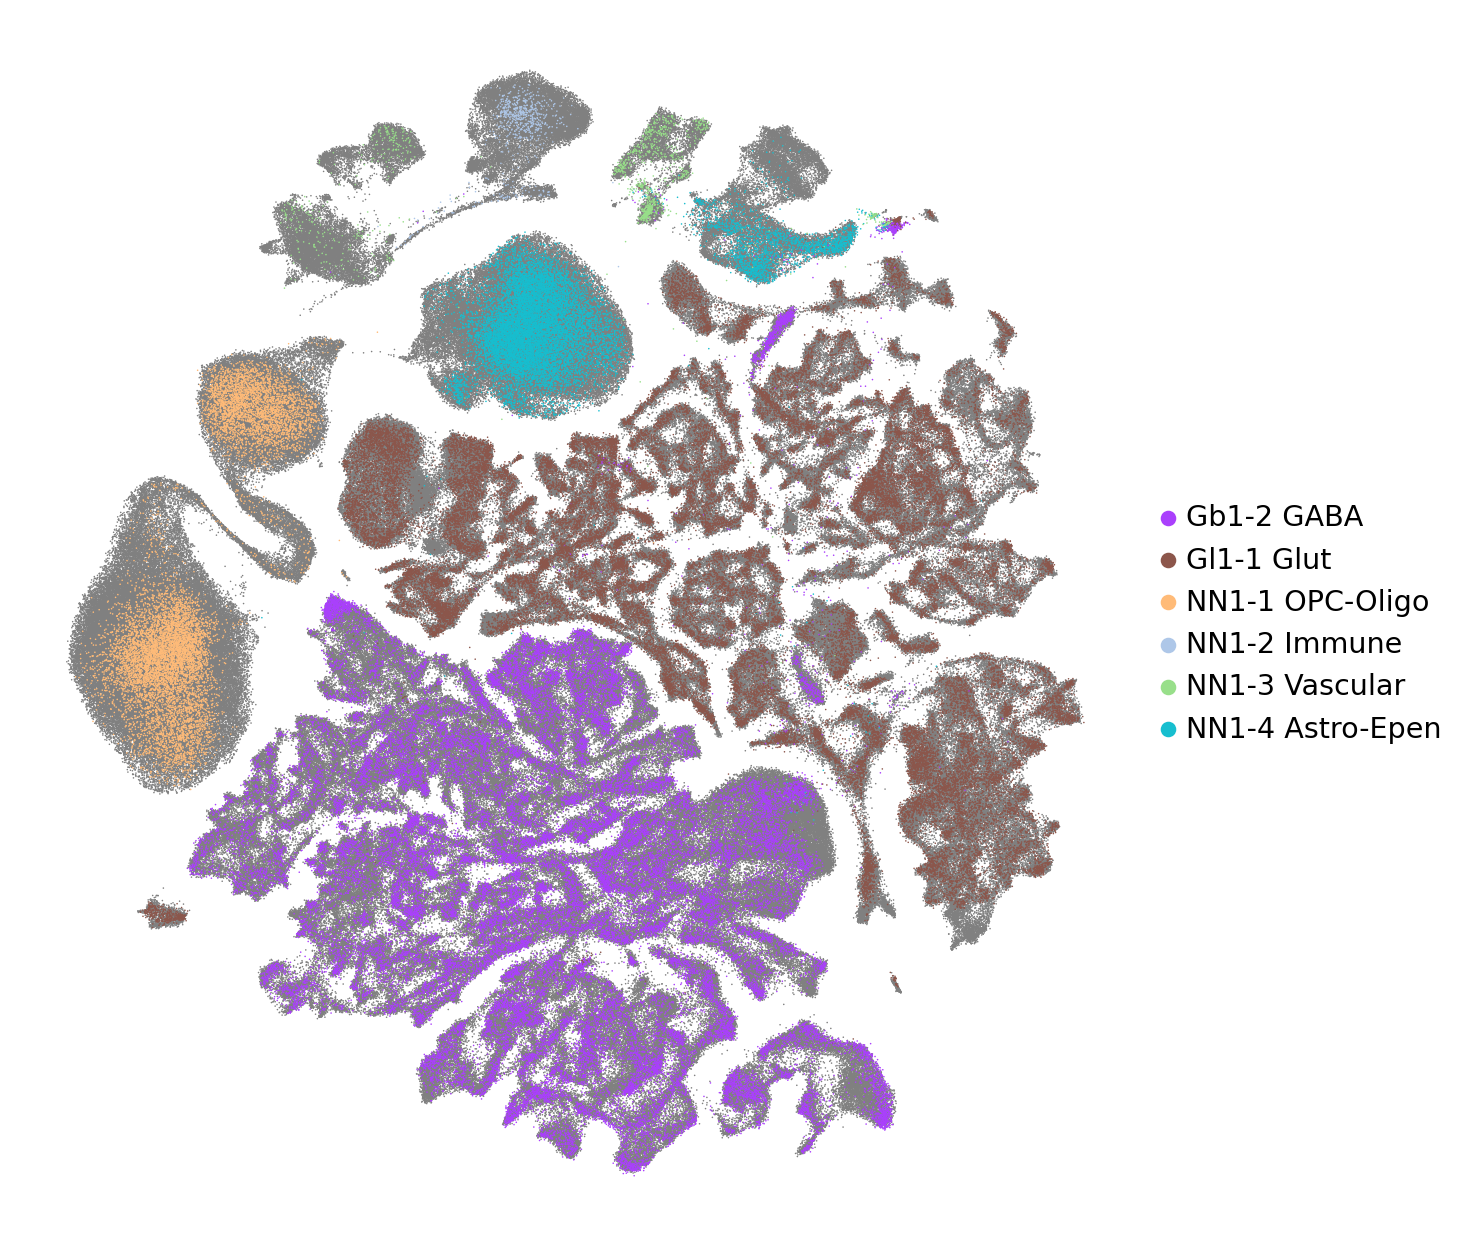

In [33]:
l1_colors = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}

scattersize=2

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot SC cells in gray
sc.pl.umap(
    ref_adata,
    color="L1_descr",  
    ax=ax,
    show=False,
    palette=["grey"], 
    s=scattersize,
    legend_loc=None
)

# 2. Plot own cells with L1 palette
sc.pl.umap(
    query_all_genes,
    color="L1_descr_assigned",
    palette=l1_colors,  
    ax=ax,
    show=False,
    s=scattersize,
)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

# Saving the adata

Change the path to your heart's content.

In [34]:
OUT_PATH = "path/to/your/directory/adata_with_hypomap3d_labels.h5ad"  

In [ ]:
query_all_genes.write_h5ad(OUT_PATH)